# 03 — Baza de date și staționaritate

In [1]:
import sys
import warnings
from pathlib import Path

# Face pachetul `src` importabil indiferent din ce folder se pornește notebookul
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore")

from src import config, data, plots
from src.stationarity import stationarity_table

## 1. Crearea bazei de date

Seriile curățate sunt unite pe dată (zilele de tranzacționare ale BET-NG), iar valorile lipsă sunt propagate înainte. Coloane:

- `Pret_<X>` — preț / nivel;
- `Rand_<X>` — randament logaritmic zilnic, `ln(P_t / P_{t-1})`;
- `Diff_ROBOR` — variația zilnică a ROBOR 3M (puncte procentuale).

In [2]:
df = data.build_master_dataset()
print(df.shape, df.index.min().date(), df.index.max().date())
df.tail()

(3844, 18) 2012-01-26 2026-10-12


,Pret_BET-NG,Pret_SNP,Pret_SNN,Pret_H2O,Pret_Brent,Pret_TTF,Pret_EUR,Pret_USD,Pret_ROBOR,Rand_BET-NG,Rand_SNP,Rand_SNN,Rand_H2O,Rand_Brent,Rand_TTF,Rand_EUR,Rand_USD,Diff_ROBOR
Data,,,,,,,,,,,,,,,,,,
2026-10-06,2062.15,1.225,61.7,180.00000,100.58,75.691,5.33704,4.7569,5.86,0.0,0.005731,0.043053,-0.001110,0.002588,0.029197,0.000889,0.004023,0.0
2026-10-07,2062.15,1.233,58.8,179.39999,100.20,78.080,5.34198,4.7472,5.86,0.0,0.006509,-0.048142,-0.003339,-0.003785,0.031075,0.000925,-0.002041,0.0
2026-10-08,2062.15,1.234,56.3,182.00000,104.28,78.849,5.34796,4.7745,5.86,0.0,0.000811,-0.043447,0.014389,0.039911,0.009801,0.001119,0.005734,0.0
2026-10-09,2062.15,1.234,56.7,175.00000,104.72,81.434,5.33919,4.7617,5.86,0.0,0.000000,0.007080,-0.039221,0.004211,0.032258,-0.001641,-0.002685,0.0
2026-10-12,2062.15,1.243,56.9,173.60001,106.78,83.110,5.33540,4.7755,5.86,0.0,0.007267,0.003521,-0.008032,0.019481,0.020372,-0.000710,0.002894,0.0


## 2. Evoluție, ACF și PACF

In [3]:
pret_cols = [c for c in df.columns if c.startswith("Pret_")]
rand_cols = [c for c in df.columns if c.startswith(("Rand_", "Diff_"))]

for group, cols in [("preturi", pret_cols), ("randamente", rand_cols)]:
    for kind in ["series", "acf", "pacf"]:
        out = config.FIG_DIR / f"eda_{group}_{kind}.png"
        plots.plot_series_panels(df, cols, kind, out)
        print("salvat:", out.name)

salvat: eda_preturi_series.png
salvat: eda_preturi_acf.png
salvat: eda_preturi_pacf.png
salvat: eda_randamente_series.png
salvat: eda_randamente_acf.png
salvat: eda_randamente_pacf.png


## 3. Matricea de corelație

,BET-NG,OMV Petrom,Nuclearelectrica,Hidroelectrica,Petrol Brent,Gaze TTF,EUR/RON,USD/RON,ROBOR
BET-NG,1.00,0.76,0.50,0.43,0.15,-0.08,0.02,-0.02,-0.03
OMV Petrom,0.76,1.00,0.31,0.24,0.15,-0.01,0.02,-0.01,-0.01
Nuclearelectrica,0.50,0.31,1.00,0.27,0.08,-0.12,0.00,-0.03,-0.01
Hidroelectrica,0.43,0.24,0.27,1.00,-0.02,-0.03,-0.01,-0.08,-0.05
Petrol Brent,0.15,0.15,0.08,-0.02,1.00,0.20,-0.01,0.03,0.01
Gaze TTF,-0.08,-0.01,-0.12,-0.03,0.20,1.00,0.02,0.05,0.02
EUR/RON,0.02,0.02,0.00,-0.01,-0.01,0.02,1.00,0.05,-0.02
USD/RON,-0.02,-0.01,-0.03,-0.08,0.03,0.05,0.05,1.00,0.07
ROBOR,-0.03,-0.01,-0.01,-0.05,0.01,0.02,-0.02,0.07,1.00


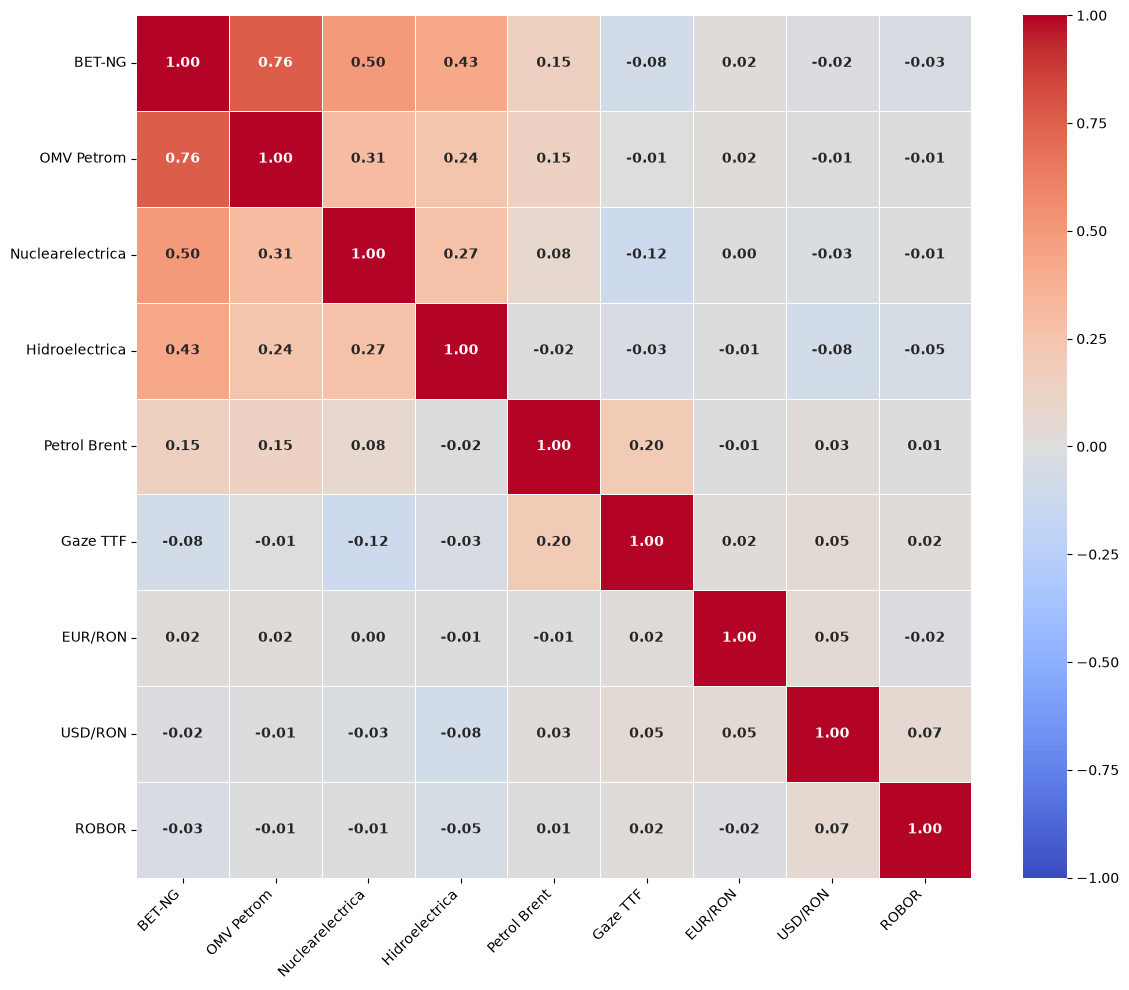

In [4]:
corr = plots.plot_correlation_heatmap(df, config.FIG_DIR / "correlation_heatmap.png")
corr.round(2)

## 4. Teste de staționaritate (ADF, Phillips-Perron, KPSS)

Serie staționară I(0) = ADF și PP resping rădăcina unitară (p < 0.05) **și** KPSS nu respinge staționaritatea (p > 0.05).

In [5]:
stationarity_table(df, config.TABLE_DIR / "stationarity_tests.csv")

,Variabilă (Serie Transformată),Statistică ADF,p-value (ADF),Statistică PP,p-value (PP),Statistică KPSS,p-value (KPSS),Decizie Finală
0,Randamentul zilnic BET-NG,-39.6326,< 0.0001,-58.2027,< 0.0001,0.3662,0.0917,Staționară I(0)
1,Randamentul zilnic OMV Petrom,-35.6779,< 0.0001,-62.5850,< 0.0001,0.4611,0.0508,Staționară I(0)
2,Randamentul zilnic Nuclearelectrica,-37.8994,< 0.0001,-53.1818,< 0.0001,0.5408,0.0325,Non-staționară / Incertă
3,Randamentul zilnic Hidroelectrica,-7.0614,< 0.0001,-27.7876,< 0.0001,0.1194,0.1000,Staționară I(0)
4,Randamentul zilnic petrol Brent,-9.5527,< 0.0001,-61.8377,< 0.0001,0.1265,0.1000,Staționară I(0)
5,Randamentul zilnic gaze TTF,-23.2696,< 0.0001,-46.7459,< 0.0001,0.0930,0.1000,Staționară I(0)
6,Randamentul zilnic EUR/RON,-15.2319,< 0.0001,-214.8935,< 0.0001,0.1085,0.1000,Staționară I(0)
7,Randamentul zilnic USD/RON,-62.3061,< 0.0001,-62.3940,< 0.0001,0.0411,0.1000,Staționară I(0)
8,Variația zilnică ROBOR (p.p.),-10.6713,< 0.0001,-45.1589,< 0.0001,0.3942,0.0797,Staționară I(0)
